# StyleBot - Entrega 2: Arquitecturas y Entrenamiento de CNN

Responsable: Juan José Aranda Flores  
Rol: Responsable de redes neuronales CNN  

Objetivo:**
Diseñar, construir y entrenar tres arquitecturas de Redes Neuronales Convolucionales (Arquitectura A sencilla, Arquitectura B intermedia y Arquitectura C profunda), evaluar el efecto del aumento de datos, implementar *Transfer Learning* con `MobileNetV2` y exportar el mejor modelo final (`.keras`) seleccionado mediante el conjunto de validación.

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

CATEGORIAS = [
    'Camiseta/top', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
    'Sandalia', 'Camisa', 'Tenis', 'Bolso', 'Botín'
]

print('TensorFlow:', tf.__version__)
print('Semilla común:', SEMILLA)
print('Categorías:', CATEGORIAS)

TensorFlow: 2.21.0
Semilla común: 42
Categorías: ['Camiseta/top', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Tenis', 'Bolso', 'Botín']


## 1. Carga y división reproducible

Fashion-MNIST contiene 60,000 imágenes oficiales para entrenamiento y 10,000 para prueba. Igual que en la Entrega 1, se separa 20 % de las 60,000 imágenes para validación mediante `train_test_split`, `random_state=42` y `stratify`. El conjunto oficial de prueba permanece intacto.

In [3]:
(X_base, y_base), (X_test_original, y_test) = tf.keras.datasets.fashion_mnist.load_data()

indices = np.arange(len(y_base), dtype=np.int64)
idx_train, idx_val = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y_base
)

X_train = X_base[idx_train].astype('float32') / 255.0
y_train = y_base[idx_train].astype('int64')
X_val = X_base[idx_val].astype('float32') / 255.0
y_val = y_base[idx_val].astype('int64')
X_test = X_test_original.astype('float32') / 255.0
y_test = y_test.astype('int64')

print('División creada con semilla 42 y estratificación.')

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
División creada con semilla 42 y estratificación.


## 2. Forma requerida por las CNN

Las imágenes originales tienen forma `(28, 28)`. Se agrega un canal para obtener `(28, 28, 1)`, que es la entrada común que utilizarán las CNN propias.

In [4]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print('Entrenamiento:', X_train.shape, y_train.shape)
print('Validación:   ', X_val.shape, y_val.shape)
print('Prueba:       ', X_test.shape, y_test.shape)
print('Tipo:', X_train.dtype)
print('Rango normalizado:', float(X_train.min()), 'a', float(X_train.max()))

Entrenamiento: (48000, 28, 28, 1) (48000,)
Validación:    (12000, 28, 28, 1) (12000,)
Prueba:        (10000, 28, 28, 1) (10000,)
Tipo: float32
Rango normalizado: 0.0 a 1.0


In [5]:
assert X_train.shape == (48000, 28, 28, 1)
assert X_val.shape == (12000, 28, 28, 1)
assert X_test.shape == (10000, 28, 28, 1)
assert X_train.dtype == np.float32
assert 0.0 <= X_train.min() and X_train.max() <= 1.0
assert set(np.unique(y_train)) == set(range(10))

conteos = pd.DataFrame({
    'categoría': CATEGORIAS,
    'entrenamiento': np.bincount(y_train, minlength=10),
    'validación': np.bincount(y_val, minlength=10),
    'prueba': np.bincount(y_test, minlength=10)
})
display(conteos)
print('Comprobaciones correctas: cantidades, forma, categorías y normalización.')

,categoría,entrenamiento,validación,prueba
0,Camiseta/top,4800,1200,1000
1,Pantalón,4800,1200,1000
2,Suéter,4800,1200,1000
3,Vestido,4800,1200,1000
4,Abrigo,4800,1200,1000
5,Sandalia,4800,1200,1000
6,Camisa,4800,1200,1000
7,Tenis,4800,1200,1000
8,Bolso,4800,1200,1000
9,Botín,4800,1200,1000


Comprobaciones correctas: cantidades, forma, categorías y normalización.


## 3. Aumento de datos exclusivo del entrenamiento

Se utilizan transformaciones pequeñas porque las prendas deben conservar su significado. La rotación, traslación y zoom se aplican en tiempo real solamente dentro de `train_ds`. Los conjuntos `val_ds` y `test_ds` no contienen estas transformaciones.

In [6]:
aumento_datos = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05, fill_mode='nearest', seed=SEMILLA),
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode='nearest', seed=SEMILLA),
    tf.keras.layers.RandomZoom(0.05, fill_mode='nearest', seed=SEMILLA),
], name='aumento_solo_entrenamiento')

BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEMILLA, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(lambda imagenes, etiquetas: (aumento_datos(imagenes, training=True), etiquetas),
         num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

print('train_ds: incluye aumento de datos')
print('val_ds:   sin aumento de datos')
print('test_ds:  sin aumento de datos')
print('Entrada CNN:', train_ds.element_spec[0].shape)

train_ds: incluye aumento de datos
val_ds:   sin aumento de datos
test_ds:  sin aumento de datos
Entrada CNN: (None, 28, 28, 1)


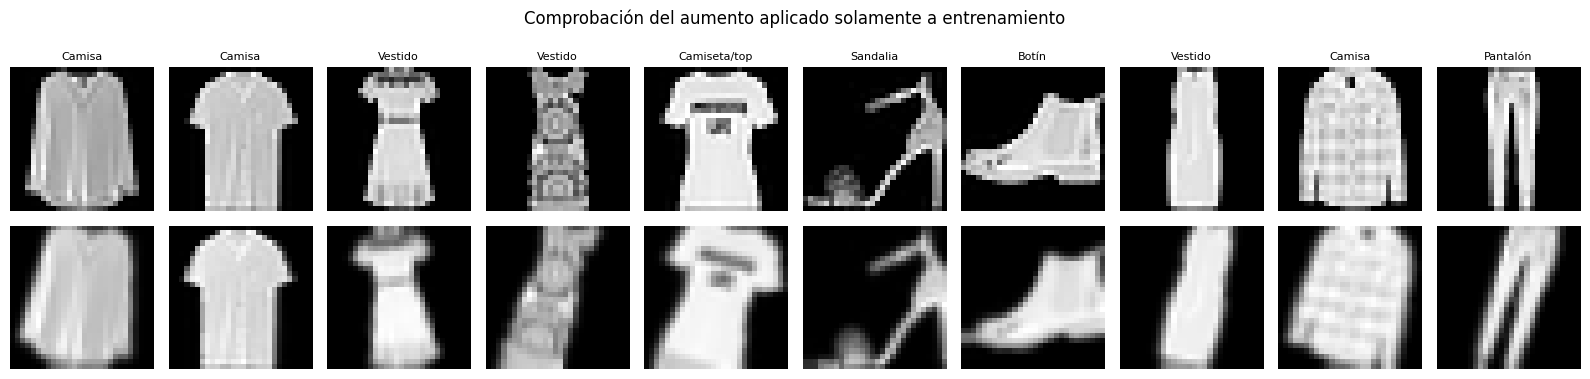

In [7]:
muestra_original = X_train[:10]
muestra_aumentada = aumento_datos(muestra_original, training=True).numpy()

fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for i in range(10):
    axes[0, i].imshow(muestra_original[i].squeeze(), cmap='gray')
    axes[0, i].set_title(CATEGORIAS[y_train[i]], fontsize=8)
    axes[0, i].axis('off')
    axes[1, i].imshow(muestra_aumentada[i].squeeze(), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=10)
axes[1, 0].set_ylabel('Aumentada', fontsize=10)
plt.suptitle('Comprobación del aumento aplicado solamente a entrenamiento')
plt.tight_layout()
plt.show()

In [8]:
X_val_control = X_val.copy()
X_test_control = X_test.copy()
_ = aumento_datos(X_train[:32], training=True)

assert np.array_equal(X_val, X_val_control)
assert np.array_equal(X_test, X_test_control)
print('Validación confirmada: X_val y X_test permanecen sin aumento.')

Validación confirmada: X_val y X_test permanecen sin aumento.


## 4. Datos que utilizará el equipo

Juan José puede utilizar `X_train`, `y_train`, `X_val`, `y_val`, `X_test` y `y_test` para las tres arquitecturas. Para entrenar con aumento debe utilizar `train_ds`; para validación y prueba debe usar `val_ds` y `test_ds`.

### Resultado esperado

- Entrenamiento: `(48000, 28, 28, 1)`
- Validación: `(12000, 28, 28, 1)`
- Prueba: `(10000, 28, 28, 1)`
- Píxeles: `float32`, entre 0 y 1
- Semilla: 42
- Aumento: solamente en `train_ds`

No se entrenó ninguna CNN en este notebook y no se utilizó prueba para elegir modelos o hiperparámetros.

## 5. Diseño de las tres arquitecturas CNN (A, B y C) y Callbacks

Se construyen tres arquitecturas convolucionales incrementando progresivamente la profundidad, el número de filtros, la normalización por lotes (`BatchNormalization`) y la regularización (`Dropout`) para comparar su capacidad de aprendizaje sobre Fashion-MNIST `(28, 28, 1)`.



In [9]:
from tensorflow.keras import layers, models, callbacks

# Función para compilar de manera uniforme todos los modelos
def compilar_modelo(modelo, lr=1e-3):
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return modelo

# ==========================================
# 1. ARQUITECTURA A (Sencilla)
# ==========================================
def crear_arquitectura_a():
    modelo = models.Sequential(name='Arquitectura_A_Sencilla')
    modelo.add(layers.Input(shape=(28, 28, 1)))

    # 1 bloque convolucional básico
    modelo.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same'))
    modelo.add(layers.MaxPooling2D((2, 2)))

    # Clasificador denso directo
    modelo.add(layers.Flatten())
    modelo.add(layers.Dense(64, activation='relu'))
    modelo.add(layers.Dense(10, activation='softmax'))
    return compilar_modelo(modelo)

# ==========================================
# 2. ARQUITECTURA B (Intermedia)
# ==========================================
def crear_arquitectura_b():
    modelo = models.Sequential(name='Arquitectura_B_Intermedia')
    modelo.add(layers.Input(shape=(28, 28, 1)))

    # Bloque 1
    modelo.add(layers.Conv2D(32, (3, 3), padding='same', use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.MaxPooling2D((2, 2)))
    modelo.add(layers.Dropout(0.25, seed=SEMILLA))

    # Bloque 2
    modelo.add(layers.Conv2D(64, (3, 3), padding='same', use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.MaxPooling2D((2, 2)))
    modelo.add(layers.Dropout(0.25, seed=SEMILLA))

    # Clasificador denso con Dropout moderado
    modelo.add(layers.Flatten())
    modelo.add(layers.Dense(128, activation='relu'))
    modelo.add(layers.Dropout(0.4, seed=SEMILLA))
    modelo.add(layers.Dense(10, activation='softmax'))
    return compilar_modelo(modelo)

# ==========================================
# 3. ARQUITECTURA C (Profunda)
# ==========================================
def crear_arquitectura_c():
    modelo = models.Sequential(name='Arquitectura_C_Profunda')
    modelo.add(layers.Input(shape=(28, 28, 1)))

    # Bloque 1 (2 capas Conv de 32 filtros)
    modelo.add(layers.Conv2D(32, (3, 3), padding='same', use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.Conv2D(32, (3, 3), padding='same', use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.MaxPooling2D((2, 2)))
    modelo.add(layers.Dropout(0.25, seed=SEMILLA))

    # Bloque 2 (2 capas Conv de 64 filtros)
    modelo.add(layers.Conv2D(64, (3, 3), padding='same', use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.Conv2D(64, (3, 3), padding='same', use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.MaxPooling2D((2, 2)))
    modelo.add(layers.Dropout(0.3, seed=SEMILLA))

    # Bloque 3 (1 capa Conv de 128 filtros)
    modelo.add(layers.Conv2D(128, (3, 3), padding='same', use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.Dropout(0.4, seed=SEMILLA))

    # Clasificador denso
    modelo.add(layers.Flatten())
    modelo.add(layers.Dense(256, use_bias=False))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.Activation('relu'))
    modelo.add(layers.Dropout(0.5, seed=SEMILLA))
    modelo.add(layers.Dense(10, activation='softmax'))
    return compilar_modelo(modelo)

# Instanciar las tres arquitecturas para verificar construcción sin errores
modelo_a = crear_arquitectura_a()
modelo_b = crear_arquitectura_b()
modelo_c = crear_arquitectura_c()

print("=== RESUMEN ARQUITECTURA A ===")
modelo_a.summary()

print("\n=== RESUMEN ARQUITECTURA B ===")
modelo_b.summary()

print("\n=== RESUMEN ARQUITECTURA C ===")
modelo_c.summary()

# Tabla comparativa de cantidad de parámetros
resumen_params = pd.DataFrame({
    'Arquitectura': ['Arquitectura A (Sencilla)', 'Arquitectura B (Intermedia)', 'Arquitectura C (Profunda)'],
    'Parámetros Totales': [modelo_a.count_params(), modelo_b.count_params(), modelo_c.count_params()],
    'Capas Convolucionales': [1, 2, 5],
    'Usa BatchNormalization': ['No', 'Sí', 'Sí'],
    'Usa Dropout': ['No', 'Sí (0.25 / 0.40)', 'Sí (0.25 / 0.30 / 0.40 / 0.50)']
})
display(resumen_params)

# ==========================================
# 4. PREPARACIÓN DE CALLBACKS
# ==========================================
def obtener_callbacks():
    early_stop = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
    return [early_stop, reduce_lr]

callbacks_base = obtener_callbacks()
print("Callbacks preparados correctamente: EarlyStopping (patience=5) y ReduceLROnPlateau (factor=0.5, patience=3).")

=== RESUMEN ARQUITECTURA A ===


Model: "Arquitectura_A_Sencilla"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,442 (1.54 MB)

 Trainable params: 402,442 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

... (10 outputs left out)

 Trainable params: 1,747,882 (6.67 MB)

 Non-trainable params: 1,152 (4.50 KB)

,Arquitectura,Parámetros Totales,Capas Convolucionales,Usa BatchNormalization,Usa Dropout
0,Arquitectura A (Sencilla),402442,1,No,No
1,Arquitectura B (Intermedia),421930,2,Sí,Sí (0.25 / 0.40)
2,Arquitectura C (Profunda),1749034,5,Sí,Sí (0.25 / 0.30 / 0.40 / 0.50)


Callbacks preparados correctamente: EarlyStopping (patience=5) y ReduceLROnPlateau (factor=0.5, patience=3).


### Explicación del cambio en profundidad, filtros, BatchNormalization y Dropout

1. **Cambio en la profundidad (número de capas):**
   * La **Arquitectura A** tiene una sola capa convolucional, por lo que únicamente capta rasgos visuales muy básicos (bordes rectos y contrastes simples).
   * La **Arquitectura B** duplica los bloques convolucionales (2 capas), permitiendo combinar bordes simples en formas intermedias (cuellos, mangas, suelas).
   * La **Arquitectura C** profundiza hasta 5 capas convolucionales organizadas en 3 bloques. Las primeras capas detectan bordes locales y las capas más profundas abstraen patrones complejos de texturas y siluetas completas de cada prenda.

2. **Aumento progresivo de filtros ($32 \rightarrow 64 \rightarrow 128$):**
   * Conforme las capas `MaxPooling2D((2, 2))` reducen las dimensiones espaciales de la imagen ($28\times28 \rightarrow 14\times14 \rightarrow 7\times7$), se incrementa la cantidad de filtros ($32 \rightarrow 64 \rightarrow 128$) para conservar y enriquecer la capacidad de representación, pasando de pocos mapas de características generales a muchos mapas especializados en patrones específicos.

3. **Incorporación de `BatchNormalization` y `Dropout`:**
   * En la **Arquitectura A** no se utiliza regularización porque es un modelo base (*baseline*) de baja complejidad para observar el comportamiento directo de una CNN simple.
   * En las **Arquitecturas B y C**, al aumentar el número de capas y filtros, crece el riesgo de sobreajuste (*overfitting*, memorizar los datos de entrenamiento) y de inestabilidad en los gradientes. Por ello se añade **`BatchNormalization`** (estabiliza y acelera la convergencia normalizando las activaciones internas) y **`Dropout`** gradual (apaga aleatoriamente entre el 25% y el 50% de las neuronas durante el entrenamiento para forzar a la red a aprender representaciones robustas y redundantes).

4. **Uso de Callbacks (`EarlyStopping` y `ReduceLROnPlateau`):**
   * **`EarlyStopping`:** Monitorea `val_loss` y detiene el entrenamiento si la red deja de mejorar en validación durante 5 épocas seguidas, restaurando automáticamente los mejores pesos (`restore_best_weights=True`).
   * **`ReduceLROnPlateau`:** Reduce la tasa de aprendizaje a la mitad (`factor=0.5`) si la pérdida de validación se estanca por 3 épocas, permitiendo dar pasos más finos hacia el mínimo de la función de pérdida.

## 6. Entrenamiento de la Arquitectura A (Con y sin aumento de datos) y Evaluación en Validación

Se entrena la **Arquitectura A** utilizando los datos de `00_datos_cnn.ipynb` con los *callbacks* `EarlyStopping` y `ReduceLROnPlateau`. Se compara su desempeño **sin aumento de datos** (`X_train`, `y_train`) y **con aumento de datos** (`train_ds`), calculando **Accuracy** y **F1 macro** exclusivamente sobre el conjunto de validación (`val_ds`), sin utilizar el conjunto de prueba. Finalmente, se guarda el historial y el modelo en formato `.keras` dentro de `modelos/`.

=== Entrenando Arquitectura A (CON aumento de datos) ===
Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.7511 - loss: 0.6856 - val_accuracy: 0.8169 - val_loss: 0.5101 - learning_rate: 0.0010
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8169 - loss: 0.4985 - val_accuracy: 0.8453 - val_loss: 0.4286 - learning_rate: 0.0010
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8350 - loss: 0.4473 - val_accuracy: 0.8664 - val_loss: 0.3796 - learning_rate: 0.0010
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8474 - loss: 0.4153 - val_accuracy: 0.8666 - val_loss: 0.3773 - learning_rate: 0.0010
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.8535 - loss: 0.3975 - val_accuracy: 0.8722 - val_loss: 0.3586 - learning_rate: 0.0010
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8599 - loss: 0.3803 - val_accuracy: 0.8788 - val_loss: 0.3441 - learning_rate: 0.0010
Epoch 7/25
375/375 ━━━━

,Modelo / Variante,Parámetros,Épocas ejecutadas,Tiempo (s),Val Loss,Val Accuracy,Val F1 Macro
0,Arquitectura A (Con aumento),402442,25,192.80,0.2925,0.9010,0.9006
1,Arquitectura A (Sin aumento),402442,17,47.49,0.2363,0.9213,0.9215


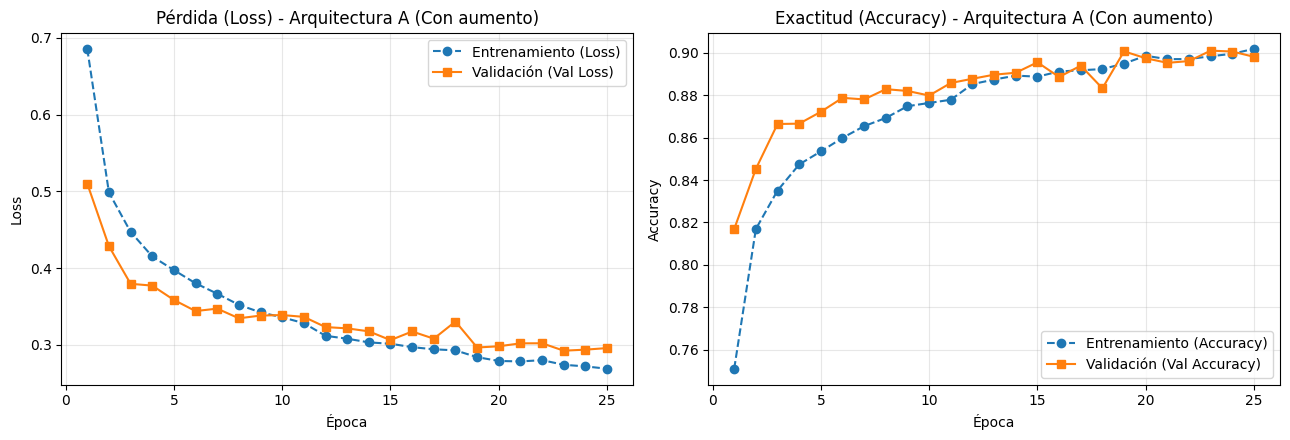

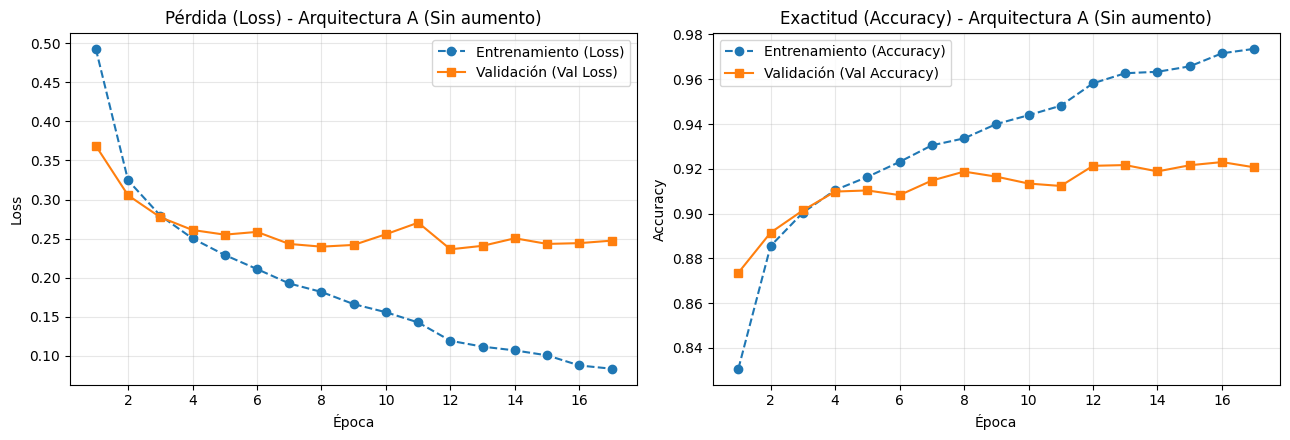

Modelo guardado exitosamente en: modelos/arquitectura_a.keras (Arquitectura A (Sin aumento))


In [10]:
import os
import time
from sklearn.metrics import accuracy_score, f1_score

os.makedirs('modelos', exist_ok=True)
os.makedirs('resultados/tablas', exist_ok=True)

EPOCAS_MAX = 25

# Preparar dataset de entrenamiento SIN aumento de datos (mismas condiciones de lote y semilla)
train_sin_aumento_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEMILLA, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Función auxiliar para evaluar Accuracy, Loss y F1 Macro en Validación (SIN tocar prueba)
def evaluar_en_validacion(modelo, dataset_val, y_real_val):
    val_loss, _ = modelo.evaluate(dataset_val, verbose=0)
    probabilidades = modelo.predict(dataset_val, verbose=0)
    predicciones = np.argmax(probabilidades, axis=1)
    acc_val = accuracy_score(y_real_val, predicciones)
    f1_macro_val = f1_score(y_real_val, predicciones, average='macro')
    return val_loss, acc_val, f1_macro_val, predicciones

# ---------------------------------------------------------
# 1. Entrenar Arquitectura A CON aumento de datos (train_ds)
# ---------------------------------------------------------
print("=== Entrenando Arquitectura A (CON aumento de datos) ===")
tf.keras.utils.set_random_seed(SEMILLA)
modelo_a_con_aug = crear_arquitectura_a()

inicio = time.perf_counter()
hist_a_con_aug = modelo_a_con_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS_MAX,
    callbacks=obtener_callbacks(),
    verbose=1
)
tiempo_a_con_aug = time.perf_counter() - inicio
val_loss_a_con, val_acc_a_con, val_f1_a_con, y_pred_val_a_con = evaluar_en_validacion(modelo_a_con_aug, val_ds, y_val)

# ---------------------------------------------------------
# 2. Entrenar Arquitectura A SIN aumento de datos
# ---------------------------------------------------------
print("\n=== Entrenando Arquitectura A (SIN aumento de datos) ===")
tf.keras.utils.set_random_seed(SEMILLA)
modelo_a_sin_aug = crear_arquitectura_a()

inicio = time.perf_counter()
hist_a_sin_aug = modelo_a_sin_aug.fit(
    train_sin_aumento_ds,
    validation_data=val_ds,
    epochs=EPOCAS_MAX,
    callbacks=obtener_callbacks(),
    verbose=1
)
tiempo_a_sin_aug = time.perf_counter() - inicio
val_loss_a_sin, val_acc_a_sin, val_f1_a_sin, y_pred_val_a_sin = evaluar_en_validacion(modelo_a_sin_aug, val_ds, y_val)

# ---------------------------------------------------------
# 3. Guardar historiales de entrenamiento
# ---------------------------------------------------------
df_hist_a_con = pd.DataFrame(hist_a_con_aug.history)
df_hist_a_sin = pd.DataFrame(hist_a_sin_aug.history)
df_hist_a_con.to_csv('resultados/tablas/historial_arquitectura_a_con_aumento.csv', index=False)
df_hist_a_sin.to_csv('resultados/tablas/historial_arquitectura_a_sin_aumento.csv', index=False)
print("\nHistoriales de entrenamiento guardados correctamente.")

# ---------------------------------------------------------
# 4. Tabla de resultados en Validación (Accuracy y F1 Macro)
# ---------------------------------------------------------
tabla_viernes_a = pd.DataFrame({
    'Modelo / Variante': ['Arquitectura A (Con aumento)', 'Arquitectura A (Sin aumento)'],
    'Parámetros': [modelo_a_con_aug.count_params(), modelo_a_sin_aug.count_params()],
    'Épocas ejecutadas': [len(hist_a_con_aug.history['loss']), len(hist_a_sin_aug.history['loss'])],
    'Tiempo (s)': [round(tiempo_a_con_aug, 2), round(tiempo_a_sin_aug, 2)],
    'Val Loss': [round(val_loss_a_con, 4), round(val_loss_a_sin, 4)],
    'Val Accuracy': [round(val_acc_a_con, 4), round(val_acc_a_sin, 4)],
    'Val F1 Macro': [round(val_f1_a_con, 4), round(val_f1_a_sin, 4)]
})
display(tabla_viernes_a)

# ---------------------------------------------------------
# 5. Gráficas de Accuracy y Pérdida (Entrenamiento vs Validación)
# ---------------------------------------------------------
def graficar_curvas_modelo(historial, titulo):
    epocas = range(1, len(historial.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Gráfica de Pérdida (Loss)
    axes[0].plot(epocas, historial.history['loss'], 'o--', label='Entrenamiento (Loss)')
    axes[0].plot(epocas, historial.history['val_loss'], 's-', label='Validación (Val Loss)')
    axes[0].set_title(f'Pérdida (Loss) - {titulo}')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Gráfica de Exactitud (Accuracy)
    axes[1].plot(epocas, historial.history['accuracy'], 'o--', label='Entrenamiento (Accuracy)')
    axes[1].plot(epocas, historial.history['val_accuracy'], 's-', label='Validación (Val Accuracy)')
    axes[1].set_title(f'Exactitud (Accuracy) - {titulo}')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

graficar_curvas_modelo(hist_a_con_aug, 'Arquitectura A (Con aumento)')
graficar_curvas_modelo(hist_a_sin_aug, 'Arquitectura A (Sin aumento)')

# ---------------------------------------------------------
# 6. Seleccionar la mejor variante de A en validación y guardar en .keras
# ---------------------------------------------------------
if val_f1_a_con >= val_f1_a_sin:
    mejor_modelo_a = modelo_a_con_aug
    nombre_mejor_a = 'Arquitectura A (Con aumento)'
else:
    mejor_modelo_a = modelo_a_sin_aug
    nombre_mejor_a = 'Arquitectura A (Sin aumento)'

ruta_modelo_a = 'modelos/arquitectura_a.keras'
mejor_modelo_a.save(ruta_modelo_a)
print(f"Modelo guardado exitosamente en: {ruta_modelo_a} ({nombre_mejor_a})")

## 7. Entrenamiento y comparación de las Arquitecturas A, B y C

Se entrenan las Arquitecturas **A**, **B** y **C** bajo exactamente las mismas condiciones (mismas épocas máximas, mismos *callbacks*, misma semilla 42 y mismos datos) para elegir la mejor arquitectura propia mediante **Accuracy** y **F1 macro** en el conjunto de validación (`val_ds`).

=== Entrenando Arquitectura B (Intermedia) ===
Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.6558 - loss: 0.9588 - val_accuracy: 0.7101 - val_loss: 0.8654 - learning_rate: 0.0010
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.7441 - loss: 0.6781 - val_accuracy: 0.8243 - val_loss: 0.4605 - learning_rate: 0.0010
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.7716 - loss: 0.6093 - val_accuracy: 0.8413 - val_loss: 0.4424 - learning_rate: 0.0010
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.7818 - loss: 0.5803 - val_accuracy: 0.8576 - val_loss: 0.3910 - learning_rate: 0.0010
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.7913 - loss: 0.5592 - val_accuracy: 0.8518 - val_loss: 0.3919 - learning_rate: 0.0010
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.8014 - loss: 0.5330 - val_accuracy: 0.8643 - val_loss: 0.3746 - learning_rate: 0.0010
Epoch 7/25
375/375 ━━━━━━━━━━

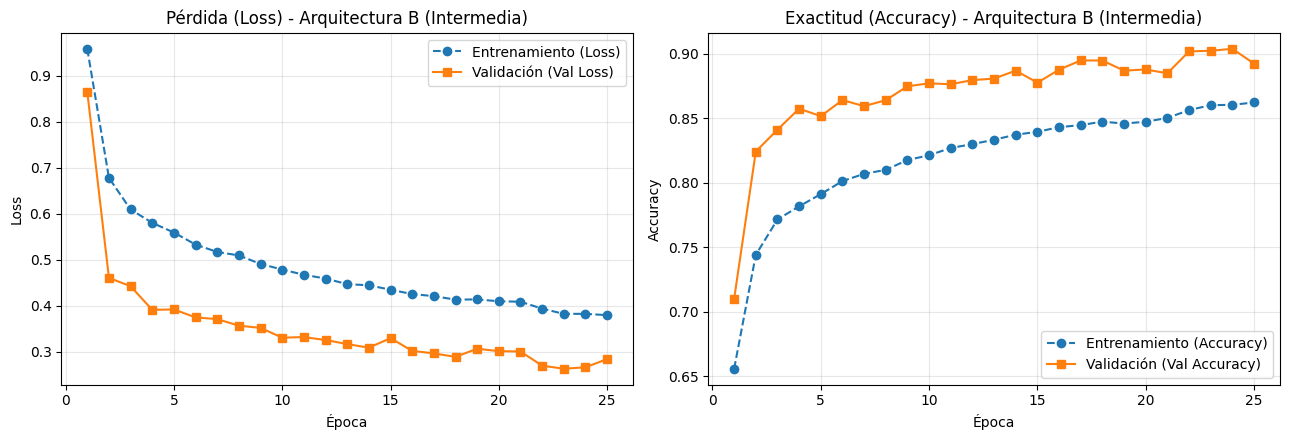

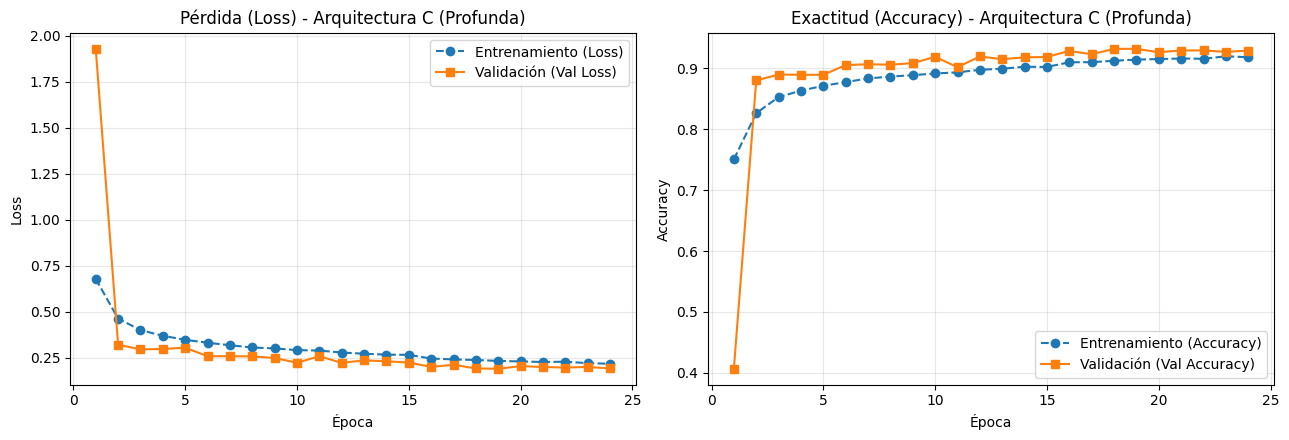

,Arquitectura,Parámetros,Épocas ejecutadas,Tiempo (s),Val Loss,Val Accuracy,Val F1 Macro
0,Arquitectura A (Sencilla),402442,25,192.80,0.2925,0.9010,0.9006
1,Arquitectura B (Intermedia),421930,25,256.45,0.2629,0.9025,0.9013
2,Arquitectura C (Profunda),1749034,24,342.20,0.1903,0.9321,0.9319


In [11]:
# Entrenar Arquitectura B en las mismas condiciones
print("=== Entrenando Arquitectura B (Intermedia) ===")
tf.keras.utils.set_random_seed(SEMILLA)
modelo_b_comp = crear_arquitectura_b()

inicio = time.perf_counter()
hist_b_comp = modelo_b_comp.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS_MAX,
    callbacks=obtener_callbacks(),
    verbose=1
)
tiempo_b_comp = time.perf_counter() - inicio
val_loss_b, val_acc_b, val_f1_b, y_pred_val_b = evaluar_en_validacion(modelo_b_comp, val_ds, y_val)

# Entrenar Arquitectura C en las mismas condiciones
print("\n=== Entrenando Arquitectura C (Profunda) ===")
tf.keras.utils.set_random_seed(SEMILLA)
modelo_c_comp = crear_arquitectura_c()

inicio = time.perf_counter()
hist_c_comp = modelo_c_comp.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCAS_MAX,
    callbacks=obtener_callbacks(),
    verbose=1
)
tiempo_c_comp = time.perf_counter() - inicio
val_loss_c, val_acc_c, val_f1_c, y_pred_val_c = evaluar_en_validacion(modelo_c_comp, val_ds, y_val)

# Guardar historiales de B y C
pd.DataFrame(hist_b_comp.history).to_csv('resultados/tablas/historial_arquitectura_b.csv', index=False)
pd.DataFrame(hist_c_comp.history).to_csv('resultados/tablas/historial_arquitectura_c.csv', index=False)

# Graficar curvas de B y C
graficar_curvas_modelo(hist_b_comp, 'Arquitectura B (Intermedia)')
graficar_curvas_modelo(hist_c_comp, 'Arquitectura C (Profunda)')

# Tabla comparativa A vs B vs C bajo las mismas condiciones (con aumento)
tabla_abc = pd.DataFrame({
    'Arquitectura': ['Arquitectura A (Sencilla)', 'Arquitectura B (Intermedia)', 'Arquitectura C (Profunda)'],
    'Parámetros': [modelo_a_con_aug.count_params(), modelo_b_comp.count_params(), modelo_c_comp.count_params()],
    'Épocas ejecutadas': [
        len(hist_a_con_aug.history['loss']),
        len(hist_b_comp.history['loss']),
        len(hist_c_comp.history['loss'])
    ],
    'Tiempo (s)': [round(tiempo_a_con_aug, 2), round(tiempo_b_comp, 2), round(tiempo_c_comp, 2)],
    'Val Loss': [round(val_loss_a_con, 4), round(val_loss_b, 4), round(val_loss_c, 4)],
    'Val Accuracy': [round(val_acc_a_con, 4), round(val_acc_b, 4), round(val_acc_c, 4)],
    'Val F1 Macro': [round(val_f1_a_con, 4), round(val_f1_b, 4), round(val_f1_c, 4)]
})
display(tabla_abc)

## 8. Transfer Learning con MobileNetV2

Se adapta el conjunto de datos convirtiendo las imágenes de 1 a 3 canales (`grayscale_to_rgb`) y redimensionándolas a $32 \times 32$ píxeles. Se congela inicialmente la base preentrenada de `MobileNetV2` y se entrena únicamente la cabeza clasificadora, evaluando en validación con **Accuracy** y **F1 macro**.

In [ ]:
def preparar_para_mobilenet(imagenes, etiquetas):
    img_rgb = tf.image.grayscale_to_rgb(imagenes)
    img_resized = tf.image.resize(img_rgb, [32, 32])
    return img_resized, etiquetas

train_tl_ds = train_ds.map(preparar_para_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_tl_ds = val_ds.map(preparar_para_mobilenet, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

tf.keras.utils.set_random_seed(SEMILLA)
base_mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(32, 32, 3),
    include_top=False,
    weights='imagenet'
)
base_mobilenet.trainable = False

entradas_tl = layers.Input(shape=(32, 32, 3), name='entrada_rgb_32x32')
x = layers.Rescaling(scale=2.0, offset=-1.0, name='escalado_mobilenet')(entradas_tl)
x = base_mobilenet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3, seed=SEMILLA)(x)
salidas_tl = layers.Dense(10, activation='softmax')(x)

modelo_mobilenet = models.Model(inputs=entradas_tl, outputs=salidas_tl, name='MobileNetV2_TransferLearning')
compilar_modelo(modelo_mobilenet, lr=1e-3)
modelo_mobilenet.summary()

inicio = time.perf_counter()
hist_mobilenet = modelo_mobilenet.fit(
    train_tl_ds,
    validation_data=val_tl_ds,
    epochs=EPOCAS_MAX,
    callbacks=obtener_callbacks(),
    verbose=1
)
tiempo_mobilenet = time.perf_counter() - inicio
val_loss_tl, val_acc_tl, val_f1_tl, y_pred_val_tl = evaluar_en_validacion(modelo_mobilenet, val_tl_ds, y_val)

pd.DataFrame(hist_mobilenet.history).to_csv('resultados/tablas/historial_mobilenetv2.csv', index=False)
graficar_curvas_modelo(hist_mobilenet, 'MobileNetV2 (Base Congelada)')

print(f"MobileNetV2 -> Tiempo: {tiempo_mobilenet:.2f}s | Val Loss: {val_loss_tl:.4f} | Val Acc: {val_acc_tl:.4f} | Val F1 Macro: {val_f1_tl:.4f}")

/tmp/ipykernel_8758/4116997964.py:10: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_mobilenet = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_TransferLearning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada_rgb_32x32 (InputLayer)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ escalado_mobilenet (Rescaling)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1, 1, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,428,362 (9.26 MB)

 Trainable params: 167,818 (655.54 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.3205 - loss: 1.8118 - val_accuracy: 0.3902 - val_loss: 1.6466 - learning_rate: 0.0010
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.3492 - loss: 1.7032 - val_accuracy: 0.3919 - val_loss: 1.6195 - learning_rate: 0.0010
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.3554 - loss: 1.6849 - val_accuracy: 0.3939 - val_loss: 1.6388 - learning_rate: 0.0010
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.3611 - loss: 1.6756 - val_accuracy: 0.3938 - val_loss: 1.6483 - learning_rate: 0.0010
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3701 - loss: 1.6681
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.3653 - loss: 1.6706 - val_accuracy: 0.3988 - val_loss: 1.6314 - learning_rate: 0.0010
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.3660 - los

## 9. Selección del mejor modelo CNN en Validación y Guardado Final (`.keras`)

Se comparan todos los modelos entrenados utilizando exclusivamente las métricas de validación (**Val Accuracy** y **Val F1 Macro**, sin emplear el conjunto de prueba para la selección). Se guarda la mejor CNN propia en `modelos/stylebot_cnn_final.keras` y se verifica que el archivo pueda recargarse sin errores.

In [ ]:
tabla_resumen_final = pd.DataFrame({
    'Modelo': [
        'Arquitectura A (Sin aumento)',
        'Arquitectura A (Con aumento)',
        'Arquitectura B (Intermedia)',
        'Arquitectura C (Profunda)',
        'MobileNetV2 (Transfer Learning)'
    ],
    'Parámetros': [
        modelo_a_sin_aug.count_params(),
        modelo_a_con_aug.count_params(),
        modelo_b_comp.count_params(),
        modelo_c_comp.count_params(),
        modelo_mobilenet.count_params()
    ],
    'Tiempo (s)': [
        round(tiempo_a_sin_aug, 2),
        round(tiempo_a_con_aug, 2),
        round(tiempo_b_comp, 2),
        round(tiempo_c_comp, 2),
        round(tiempo_mobilenet, 2)
    ],
    'Val Loss': [
        round(val_loss_a_sin, 4),
        round(val_loss_a_con, 4),
        round(val_loss_b, 4),
        round(val_loss_c, 4),
        round(val_loss_tl, 4)
    ],
    'Val Accuracy': [
        round(val_acc_a_sin, 4),
        round(val_acc_a_con, 4),
        round(val_acc_b, 4),
        round(val_acc_c, 4),
        round(val_acc_tl, 4)
    ],
    'Val F1 Macro': [
        round(val_f1_a_sin, 4),
        round(val_f1_a_con, 4),
        round(val_f1_b, 4),
        round(val_f1_c, 4),
        round(val_f1_tl, 4)
    ]
})

print("=== TABLA COMPARATIVA GLOBAL (EVALUACIÓN EN VALIDACIÓN) ===")
display(tabla_resumen_final)
tabla_resumen_final.to_csv('resultados/tablas/comparacion_modelos_cnn_validacion.csv', index=False)

# Selección automática de la mejor CNN propia según F1 Macro en Validación
candidatos_cnn = {
    'Arquitectura A (Sin aumento)': (modelo_a_sin_aug, val_acc_a_sin, val_f1_a_sin),
    'Arquitectura A (Con aumento)': (modelo_a_con_aug, val_acc_a_con, val_f1_a_con),
    'Arquitectura B (Intermedia)': (modelo_b_comp, val_acc_b, val_f1_b),
    'Arquitectura C (Profunda)': (modelo_c_comp, val_acc_c, val_f1_c)
}

mejor_nombre, (mejor_modelo_cnn, mejor_acc, mejor_f1) = max(candidatos_cnn.items(), key=lambda x: x[1][2])
print(f"\nMejor CNN propia elegida por validación: {mejor_nombre}")
print(f"Val Accuracy: {mejor_acc:.4f} | Val F1 Macro: {mejor_f1:.4f}")

# Guardar en modelos/stylebot_cnn_final.keras y verificar recarga
ruta_final = 'modelos/stylebot_cnn_final.keras'
mejor_modelo_cnn.save(ruta_final)

modelo_verificado = tf.keras.models.load_model(ruta_final)
_, acc_verif, f1_verif, _ = evaluar_en_validacion(modelo_verificado, val_ds, y_val)
print(f"Verificación exitosa de {ruta_final} -> Val Acc: {acc_verif:.4f} | Val F1 Macro: {f1_verif:.4f}")

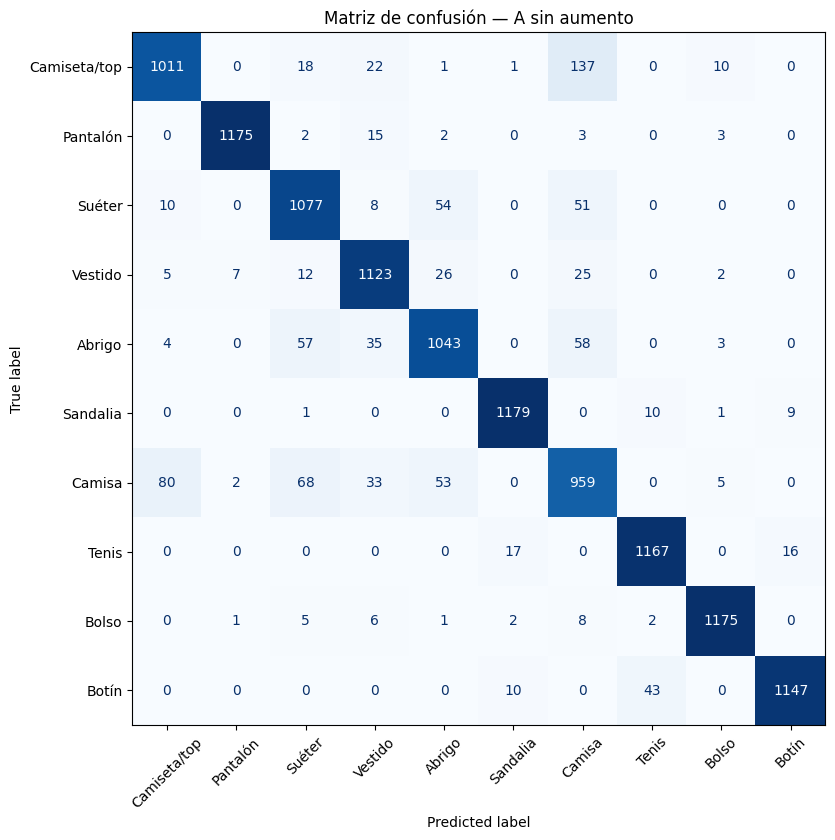

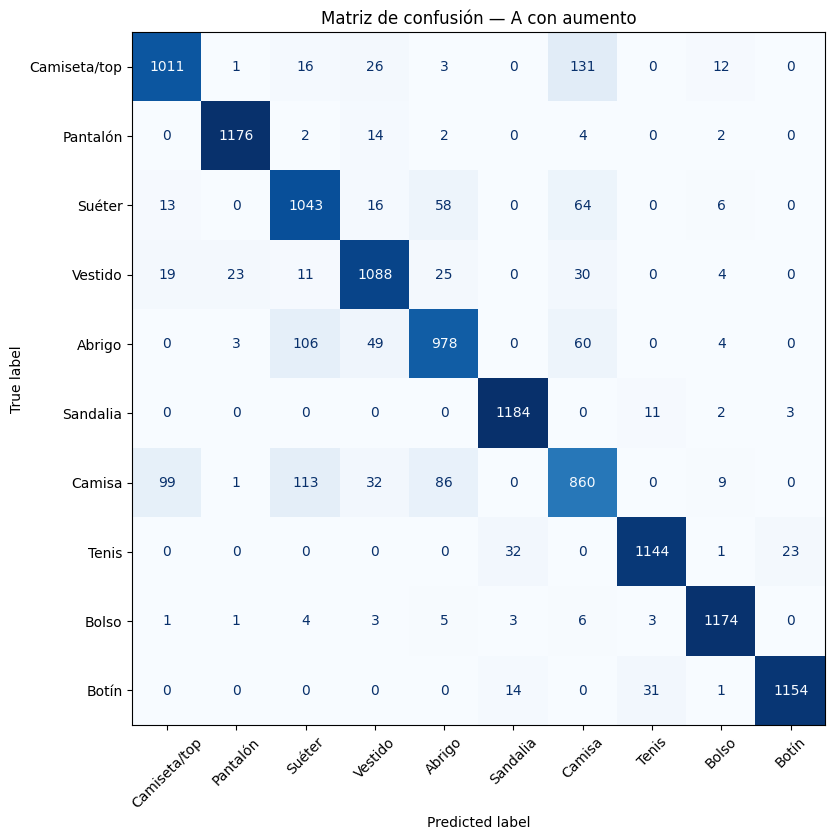

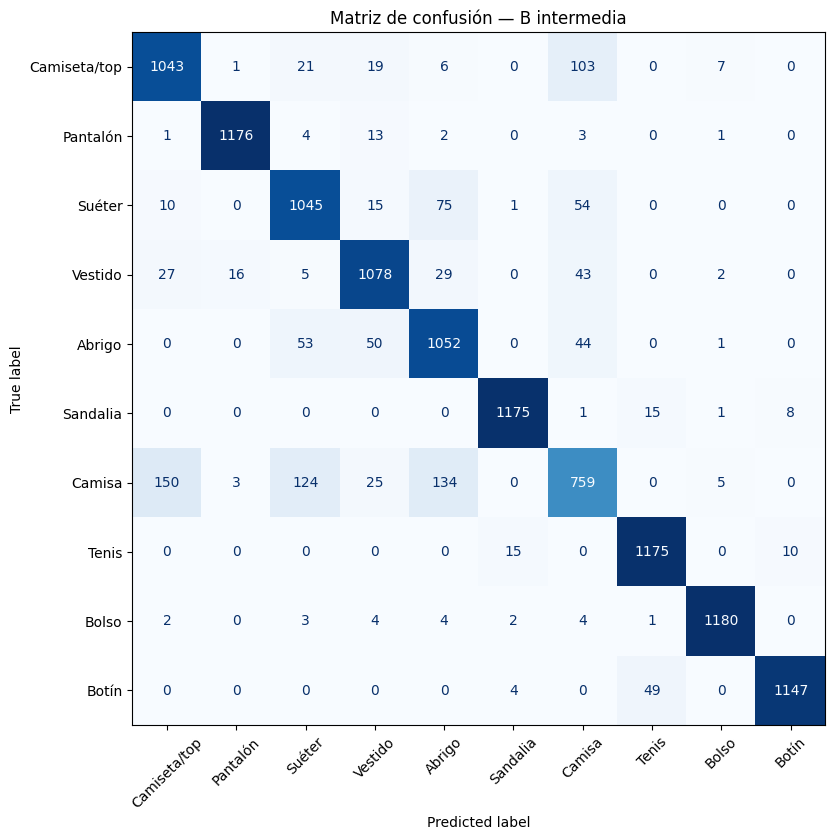

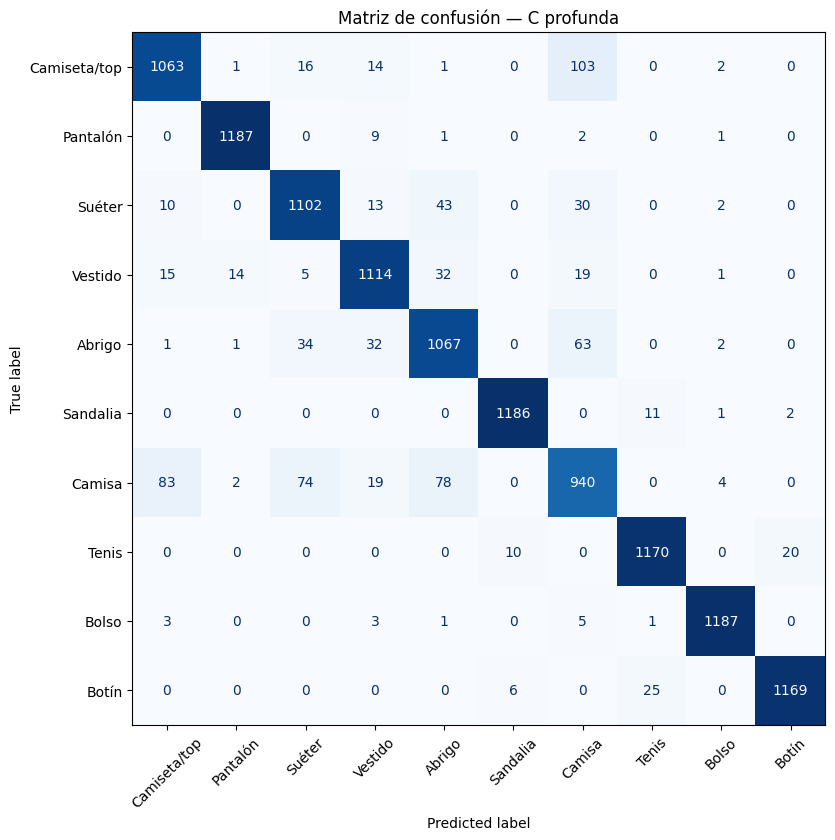

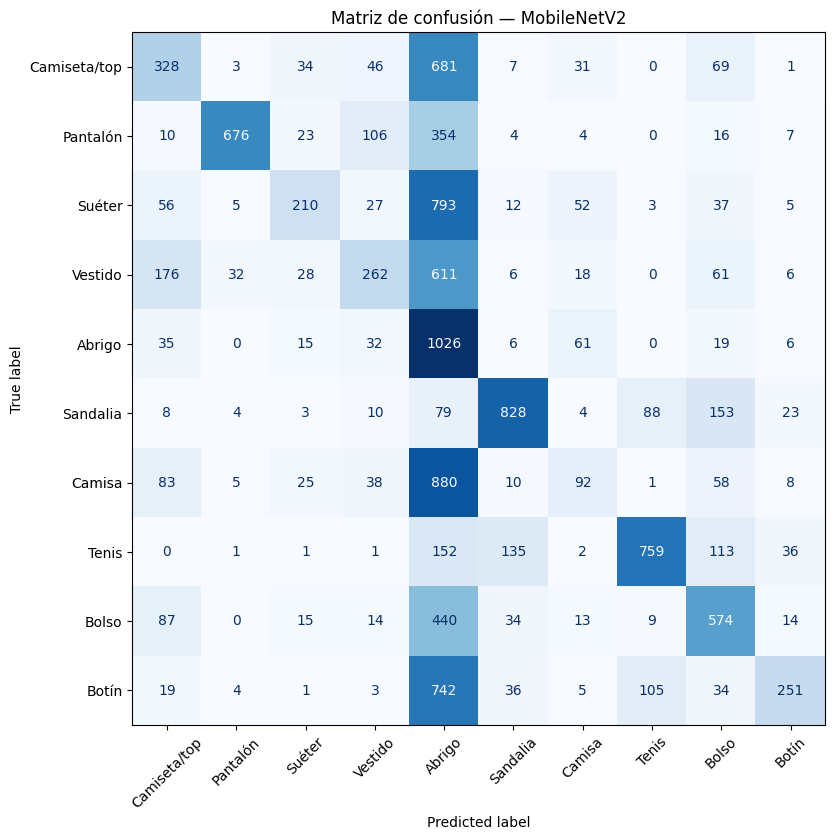

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro
0,A sin aumento,0.921333,0.922060,0.921333,0.921458
1,A con aumento,0.901000,0.900836,0.901000,0.900648
2,B intermedia,0.902500,0.901548,0.902500,0.901272
3,C profunda,0.932083,0.931832,0.932083,0.931902
4,MobileNetV2,0.417167,0.568094,0.417167,0.426106


In [15]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

modelos_a_evaluar = {
    "A sin aumento": (modelo_a_sin_aug, val_ds),
    "A con aumento": (modelo_a_con_aug, val_ds),
    "B intermedia": (modelo_b_comp, val_ds),
    "C profunda": (modelo_c_comp, val_ds),
    "MobileNetV2": (modelo_mobilenet, val_tl_ds)
}

resultados_metricas = []

for nombre, (modelo, datos_validacion) in modelos_a_evaluar.items():
    probabilidades = modelo.predict(datos_validacion, verbose=0)
    predicciones = np.argmax(probabilidades, axis=1)

    accuracy = accuracy_score(y_val, predicciones)
    precision = precision_score(y_val, predicciones, average="macro", zero_division=0)
    recall = recall_score(y_val, predicciones, average="macro", zero_division=0)
    f1 = f1_score(y_val, predicciones, average="macro", zero_division=0)

    resultados_metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy,
        "Precision macro": precision,
        "Recall macro": recall,
        "F1 macro": f1
    })

    matriz = confusion_matrix(y_val, predicciones)
    fig, ax = plt.subplots(figsize=(9, 9))
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CATEGORIAS
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    plt.title(f"Matriz de confusión — {nombre}")
    plt.show()

tabla_metricas = pd.DataFrame(resultados_metricas)
display(tabla_metricas)
tabla_metricas.to_csv(
    "resultados/tablas/metricas_y_matrices_validacion.csv",
    index=False
)

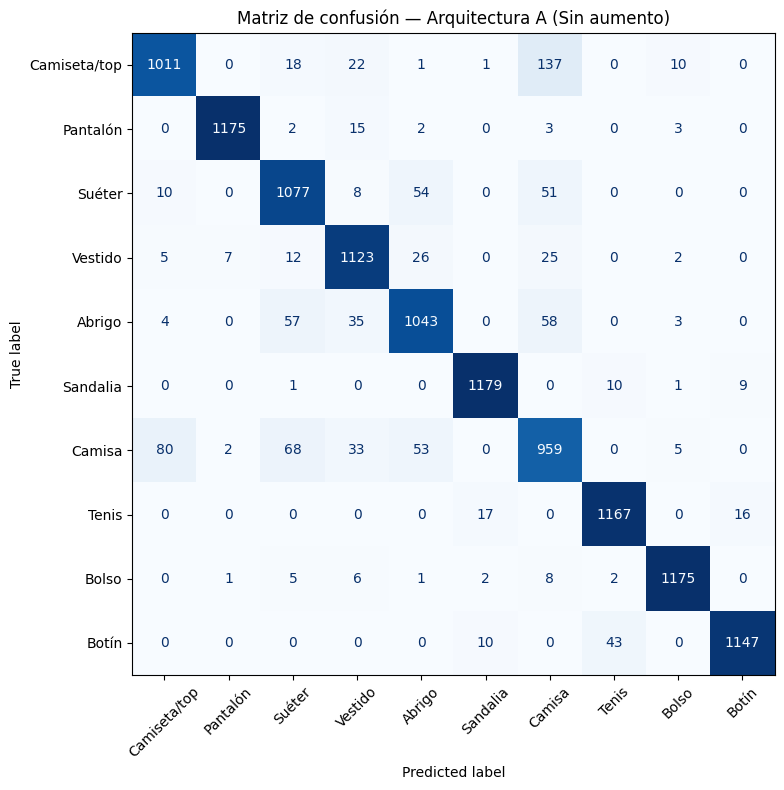

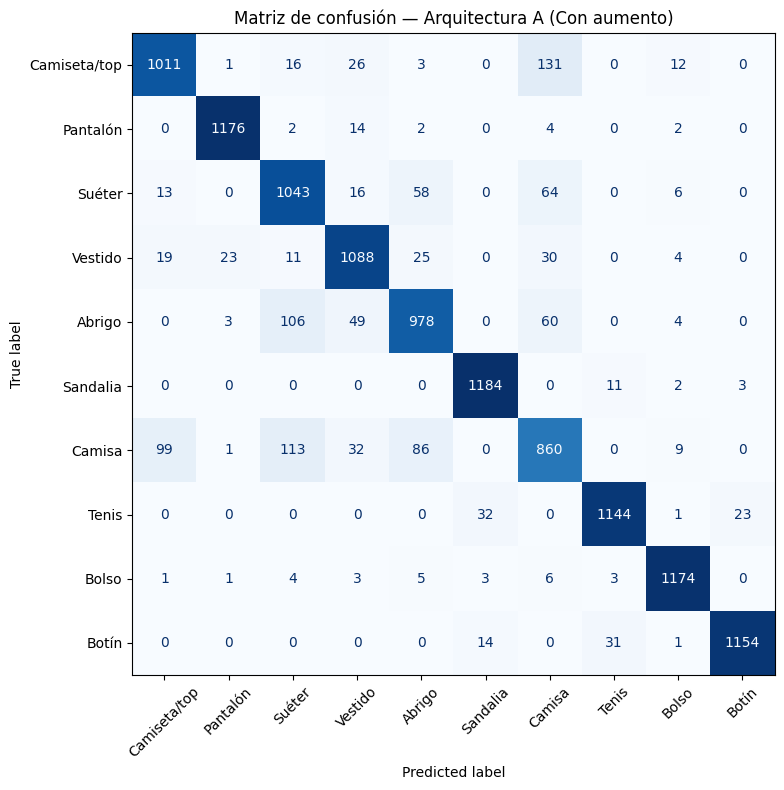

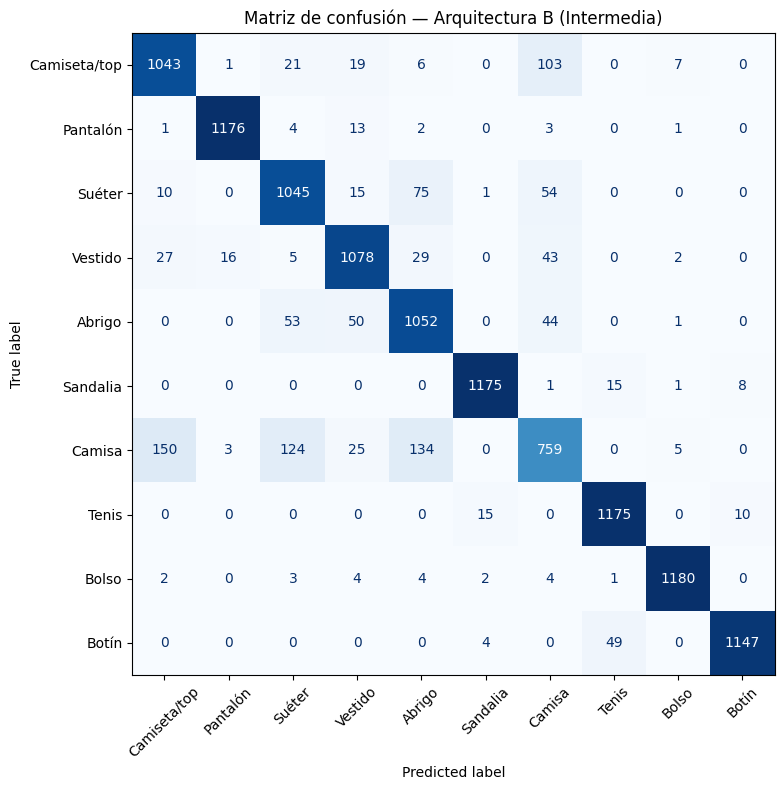

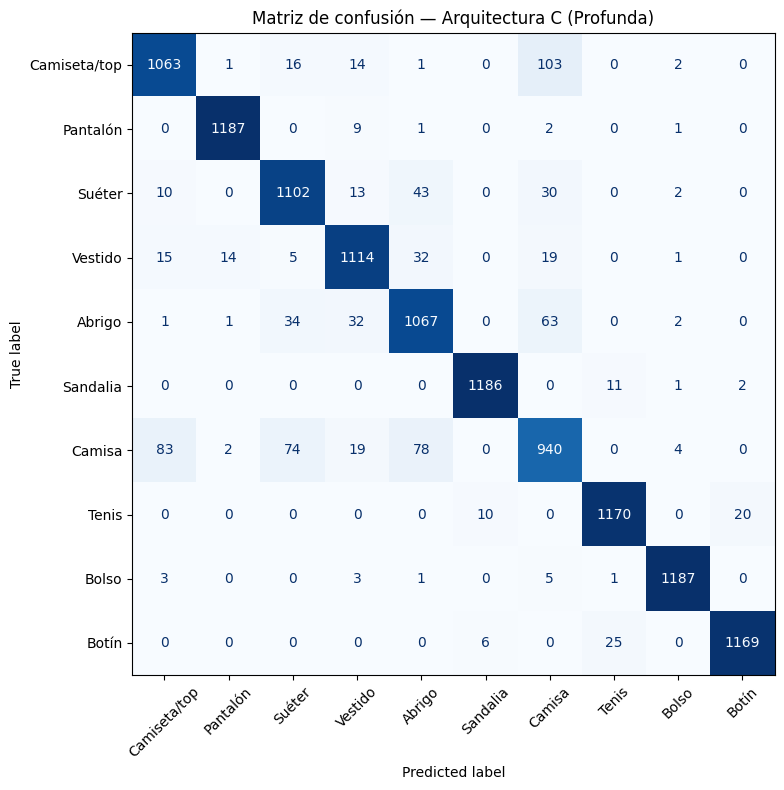

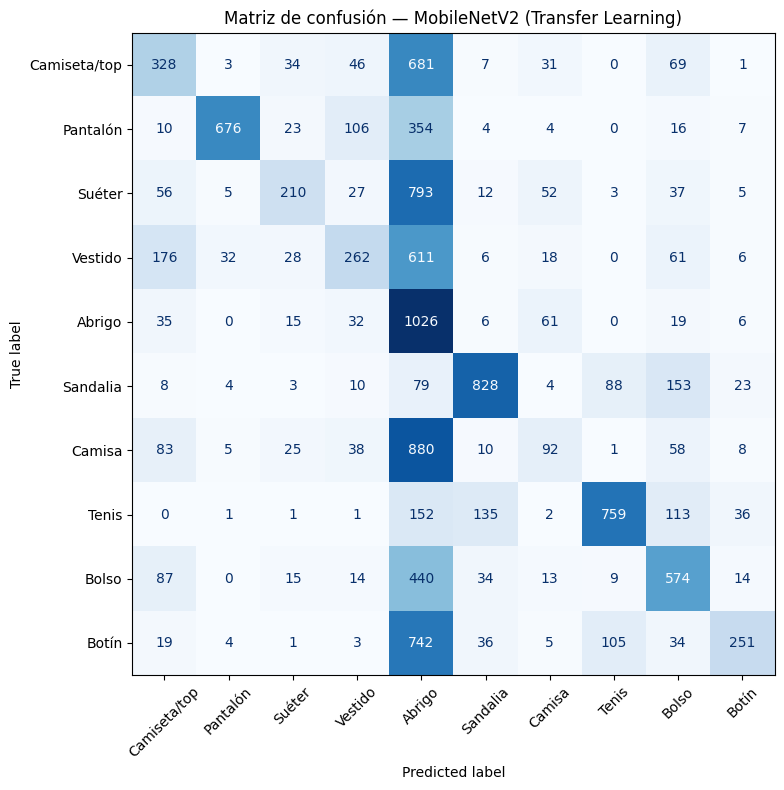


=== Entrenando modelo clásico HOG + Hu ===
HOG + Hu entrenamiento: 5000/48000
HOG + Hu entrenamiento: 10000/48000
HOG + Hu entrenamiento: 15000/48000
HOG + Hu entrenamiento: 20000/48000
HOG + Hu entrenamiento: 25000/48000
HOG + Hu entrenamiento: 30000/48000
HOG + Hu entrenamiento: 35000/48000
HOG + Hu entrenamiento: 40000/48000
HOG + Hu entrenamiento: 45000/48000
HOG + Hu validación: 5000/12000
HOG + Hu validación: 10000/12000
HOG + Hu prueba: 5000/10000
HOG + Hu prueba: 10000/10000
Fitting 3 folds for each of 4 candidates, totalling 12 fits


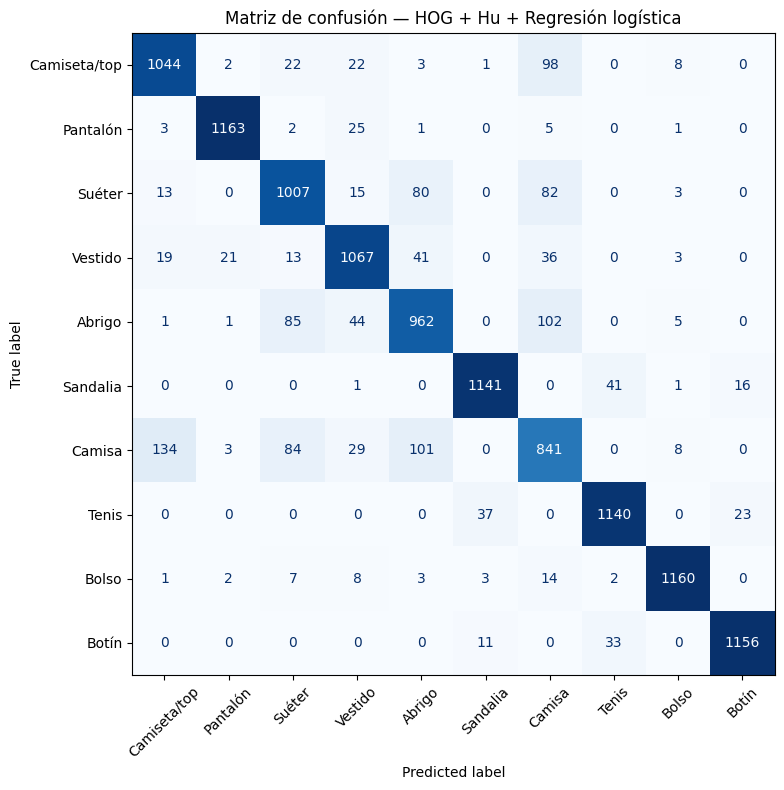


=== TABLA DEFINITIVA DE VALIDACIÓN ===


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Tiempo entrenamiento (s),Número de parámetros,Tamaño modelo (MB)
0,Arquitectura C (Profunda),0.9321,0.9318,0.9321,0.9319,342.2000,1749034,20.1075
1,Arquitectura A (Sin aumento),0.9213,0.9221,0.9213,0.9215,47.4900,402442,4.6343
2,Arquitectura B (Intermedia),0.9025,0.9015,0.9025,0.9013,256.4500,421930,4.8833
3,Arquitectura A (Con aumento),0.9010,0.9008,0.9010,0.9006,192.8000,402442,4.6343
4,HOG + Hu + Regresión logística,0.8901,0.8900,0.8901,0.8900,145.1712,13040,0.1306
5,MobileNetV2 (Transfer Learning),0.4172,0.5681,0.4172,0.4261,322.7100,2428362,11.1175



=== ERRORES MÁS FRECUENTES EN VALIDACIÓN ===


,Modelo,Clase real,Predicción incorrecta,Cantidad de errores
0,Arquitectura A (Sin aumento),Camiseta/top,Camisa,137
1,Arquitectura A (Sin aumento),Camisa,Camiseta/top,80
2,Arquitectura A (Sin aumento),Camisa,Suéter,68
3,Arquitectura A (Sin aumento),Abrigo,Camisa,58
4,Arquitectura A (Sin aumento),Abrigo,Suéter,57
5,Arquitectura A (Con aumento),Camiseta/top,Camisa,131
6,Arquitectura A (Con aumento),Camisa,Suéter,113
7,Arquitectura A (Con aumento),Abrigo,Suéter,106
8,Arquitectura A (Con aumento),Camisa,Camiseta/top,99
9,Arquitectura A (Con aumento),Camisa,Abrigo,86



Mejor CNN propia: Arquitectura C (Profunda)


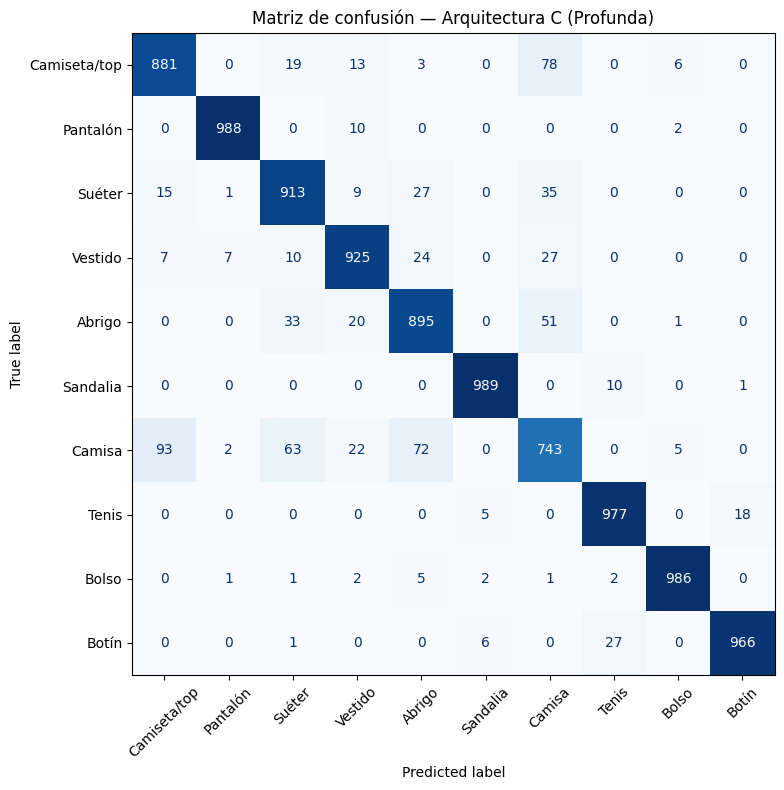

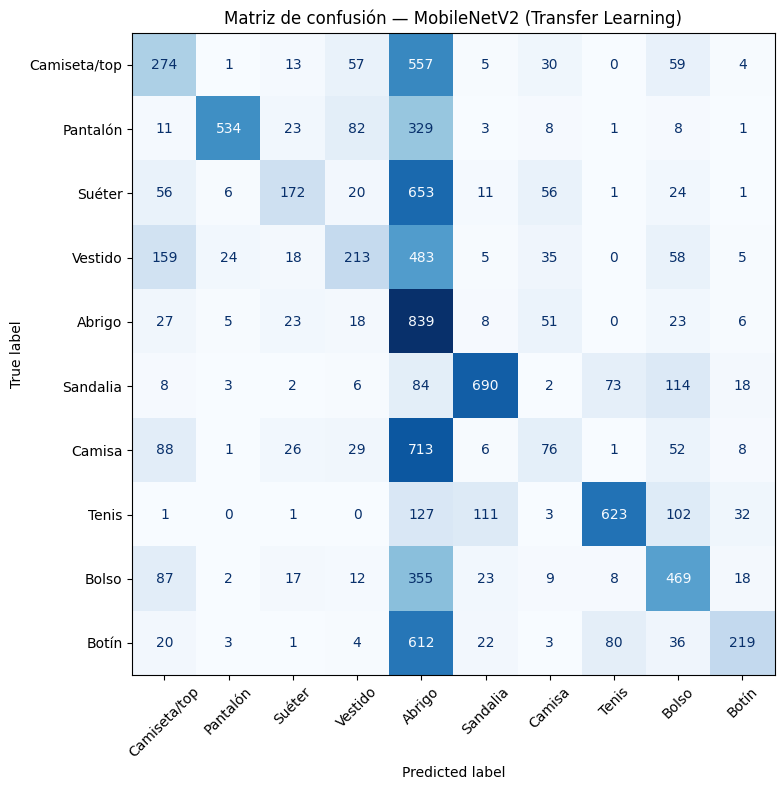

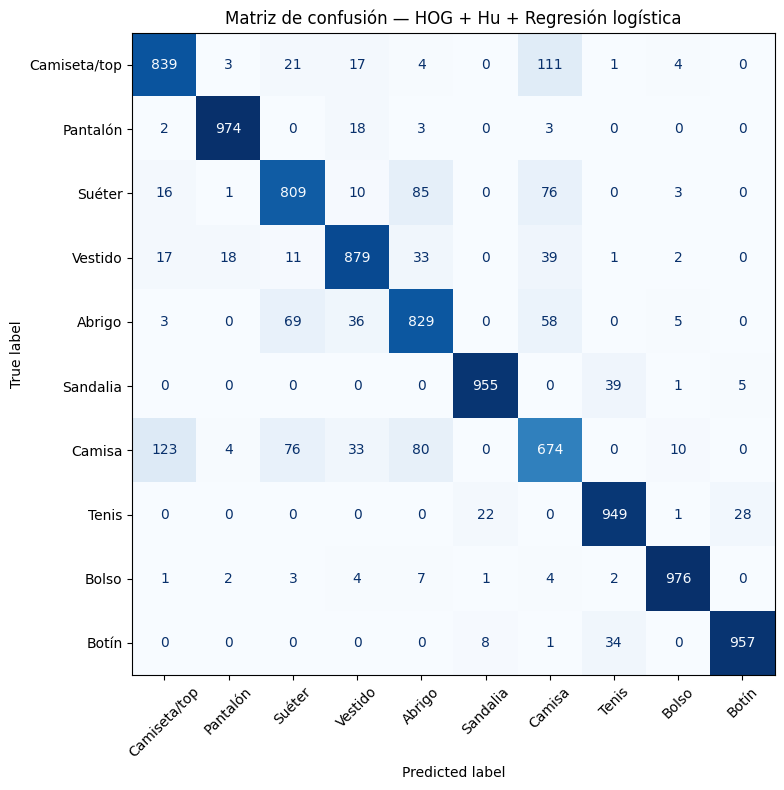


=== TABLA FINAL DE PRUEBA ===


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro
0,Arquitectura C (Profunda),0.9263,0.9258,0.9263,0.9259
1,HOG + Hu + Regresión logística,0.8841,0.8838,0.8841,0.8839
2,MobileNetV2 (Transfer Learning),0.4109,0.5587,0.4109,0.4211



=== ERRORES MÁS FRECUENTES EN PRUEBA ===


,Modelo,Clase real,Predicción incorrecta,Cantidad de errores
0,Arquitectura C (Profunda),Camisa,Camiseta/top,93
1,Arquitectura C (Profunda),Camiseta/top,Camisa,78
2,Arquitectura C (Profunda),Camisa,Abrigo,72
3,Arquitectura C (Profunda),Camisa,Suéter,63
4,Arquitectura C (Profunda),Abrigo,Camisa,51
5,MobileNetV2 (Transfer Learning),Camisa,Abrigo,713
6,MobileNetV2 (Transfer Learning),Suéter,Abrigo,653
7,MobileNetV2 (Transfer Learning),Botín,Abrigo,612
8,MobileNetV2 (Transfer Learning),Camiseta/top,Abrigo,557
9,MobileNetV2 (Transfer Learning),Vestido,Abrigo,483



TERMINADO
Carpeta: resultados/entrega2
ZIP: /content/resultados_entrega2.zip


In [16]:
# ============================================================
# ENTREGA 2 — EVALUACIÓN COMPLETA Y RESULTADOS FINALES
# Ejecutar al final de 01_arquitecturas_cnn.ipynb
# ============================================================

!pip -q install scikit-image

import os
import re
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from skimage.feature import hog
from skimage.measure import moments_central, moments_normalized, moments_hu

# ---------- Carpetas ----------
SALIDA = "resultados/entrega2"
MATRICES_VAL = f"{SALIDA}/matrices_validacion"
MATRICES_TEST = f"{SALIDA}/matrices_prueba"
TEMP_MODELOS = "/content/tamanos_modelos"

for carpeta in [SALIDA, MATRICES_VAL, MATRICES_TEST, TEMP_MODELOS]:
    os.makedirs(carpeta, exist_ok=True)

# ---------- Funciones ----------
def metricas(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision macro": precision_score(
            y_real, y_pred, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_real, y_pred, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_real, y_pred, average="macro", zero_division=0
        )
    }

def nombre_archivo(texto):
    return re.sub(r"[^a-zA-Z0-9]+", "_", texto).strip("_").lower()

def guardar_matriz(y_real, y_pred, nombre, carpeta):
    matriz = confusion_matrix(y_real, y_pred)

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CATEGORIAS
    ).plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False
    )

    plt.title(f"Matriz de confusión — {nombre}")
    plt.tight_layout()

    ruta = f"{carpeta}/{nombre_archivo(nombre)}.png"
    plt.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    return matriz

def principales_errores(matriz, nombre, cantidad=5):
    sin_diagonal = matriz.copy()
    np.fill_diagonal(sin_diagonal, 0)

    filas = []
    for _ in range(cantidad):
        real, predicho = np.unravel_index(
            np.argmax(sin_diagonal),
            sin_diagonal.shape
        )

        errores = int(sin_diagonal[real, predicho])

        if errores == 0:
            break

        filas.append({
            "Modelo": nombre,
            "Clase real": CATEGORIAS[real],
            "Predicción incorrecta": CATEGORIAS[predicho],
            "Cantidad de errores": errores
        })

        sin_diagonal[real, predicho] = 0

    return filas

def tamano_keras(modelo, nombre):
    ruta = f"{TEMP_MODELOS}/{nombre_archivo(nombre)}.keras"
    modelo.save(ruta, overwrite=True)
    return os.path.getsize(ruta) / (1024 * 1024)

# ============================================================
# 1. VALIDACIÓN: A, B, C Y MOBILENETV2
# ============================================================

modelos_cnn = {
    "Arquitectura A (Sin aumento)": (modelo_a_sin_aug, val_ds),
    "Arquitectura A (Con aumento)": (modelo_a_con_aug, val_ds),
    "Arquitectura B (Intermedia)": (modelo_b_comp, val_ds),
    "Arquitectura C (Profunda)": (modelo_c_comp, val_ds),
    "MobileNetV2 (Transfer Learning)": (modelo_mobilenet, val_tl_ds)
}

tiempos_cnn = dict(
    zip(
        tabla_resumen_final["Modelo"],
        tabla_resumen_final["Tiempo (s)"]
    )
)

filas_validacion = []
errores_validacion = []
predicciones_validacion = {}

for nombre, (modelo, dataset) in modelos_cnn.items():
    probabilidades = modelo.predict(dataset, verbose=0)
    predicciones = np.argmax(probabilidades, axis=1)
    predicciones_validacion[nombre] = predicciones

    fila = {
        "Modelo": nombre,
        **metricas(y_val, predicciones),
        "Tiempo entrenamiento (s)": tiempos_cnn[nombre],
        "Número de parámetros": modelo.count_params(),
        "Tamaño modelo (MB)": tamano_keras(modelo, nombre)
    }

    filas_validacion.append(fila)

    matriz = guardar_matriz(
        y_val, predicciones, nombre, MATRICES_VAL
    )

    errores_validacion.extend(
        principales_errores(matriz, nombre)
    )

# ============================================================
# 2. MODELO CLÁSICO: HOG + HU + REGRESIÓN LOGÍSTICA
# ============================================================

print("\n=== Entrenando modelo clásico HOG + Hu ===")
inicio_clasico = time.perf_counter()

# Las imágenes CNN tienen canal; HOG y Hu requieren 28x28.
X_train_clasico = np.squeeze(X_train, axis=-1)
X_val_clasico = np.squeeze(X_val, axis=-1)
X_test_clasico = np.squeeze(X_test, axis=-1)

def extraer_hog_hu(imagenes, conjunto):
    vectores = []

    for i, imagen in enumerate(imagenes):
        vector_hog = hog(
            imagen,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        mu = moments_central(imagen)
        nu = moments_normalized(mu)
        vector_hu = moments_hu(nu)

        # Misma transformación de Entrega 1.
        vector_hu = np.sign(vector_hu) * np.log1p(np.abs(vector_hu))

        vectores.append(
            np.concatenate([vector_hog, vector_hu])
        )

        if (i + 1) % 5000 == 0:
            print(f"{conjunto}: {i + 1}/{len(imagenes)}")

    return np.asarray(vectores, dtype=np.float32)

X_train_hog_hu = extraer_hog_hu(X_train_clasico, "HOG + Hu entrenamiento")
X_val_hog_hu = extraer_hog_hu(X_val_clasico, "HOG + Hu validación")
X_test_hog_hu = extraer_hog_hu(X_test_clasico, "HOG + Hu prueba")

idx_cv, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=12000,
    stratify=y_train,
    random_state=SEMILLA
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEMILLA
)

pipeline_hog_hu = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        tol=1e-3,
        random_state=SEMILLA
    ))
])

busqueda_hog_hu = GridSearchCV(
    estimator=pipeline_hog_hu,
    param_grid={"modelo__C": [0.01, 0.1, 1.0, 10.0]},
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

busqueda_hog_hu.fit(X_train_hog_hu[idx_cv], y_train[idx_cv])

modelo_clasico = clone(busqueda_hog_hu.best_estimator_)
modelo_clasico.fit(X_train_hog_hu, y_train)

tiempo_clasico = time.perf_counter() - inicio_clasico

pred_val_clasico = modelo_clasico.predict(X_val_hog_hu)
pred_test_clasico = modelo_clasico.predict(X_test_hog_hu)

ruta_clasico = f"{TEMP_MODELOS}/hog_hu_regresion_logistica.joblib"
joblib.dump(modelo_clasico, ruta_clasico)

parametros_clasico = (
    modelo_clasico.named_steps["modelo"].coef_.size +
    modelo_clasico.named_steps["modelo"].intercept_.size
)

filas_validacion.append({
    "Modelo": "HOG + Hu + Regresión logística",
    **metricas(y_val, pred_val_clasico),
    "Tiempo entrenamiento (s)": tiempo_clasico,
    "Número de parámetros": parametros_clasico,
    "Tamaño modelo (MB)": os.path.getsize(ruta_clasico) / (1024 * 1024)
})

matriz_val_clasico = guardar_matriz(
    y_val,
    pred_val_clasico,
    "HOG + Hu + Regresión logística",
    MATRICES_VAL
)

errores_validacion.extend(
    principales_errores(
        matriz_val_clasico,
        "HOG + Hu + Regresión logística"
    )
)

# ============================================================
# 3. TABLA DEFINITIVA DE VALIDACIÓN
# ============================================================

tabla_validacion = pd.DataFrame(filas_validacion).sort_values(
    "F1 macro",
    ascending=False
).reset_index(drop=True)

tabla_validacion.to_csv(
    f"{SALIDA}/tabla_comparativa_validacion.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_errores_validacion = pd.DataFrame(errores_validacion)
tabla_errores_validacion.to_csv(
    f"{SALIDA}/analisis_errores_validacion.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== TABLA DEFINITIVA DE VALIDACIÓN ===")
display(tabla_validacion.round(4))

print("\n=== ERRORES MÁS FRECUENTES EN VALIDACIÓN ===")
display(tabla_errores_validacion)

# La selección se hace únicamente con validación.
mejor_cnn = "Arquitectura C (Profunda)"
print(f"\nMejor CNN propia: {mejor_cnn}")

# ============================================================
# 4. PRUEBA FINAL: C, MOBILENETV2 Y MODELO CLÁSICO
# ============================================================

test_tl_ds = test_ds.map(
    preparar_para_mobilenet,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

finalistas_prueba = {
    "Arquitectura C (Profunda)": (modelo_c_comp, test_ds),
    "MobileNetV2 (Transfer Learning)": (modelo_mobilenet, test_tl_ds)
}

filas_prueba = []
errores_prueba = []

for nombre, (modelo, dataset) in finalistas_prueba.items():
    probabilidades = modelo.predict(dataset, verbose=0)
    predicciones = np.argmax(probabilidades, axis=1)

    filas_prueba.append({
        "Modelo": nombre,
        **metricas(y_test, predicciones)
    })

    matriz = guardar_matriz(
        y_test,
        predicciones,
        nombre,
        MATRICES_TEST
    )

    errores_prueba.extend(
        principales_errores(matriz, nombre)
    )

# Agregar el resultado real del modelo clásico.
filas_prueba.append({
    "Modelo": "HOG + Hu + Regresión logística",
    **metricas(y_test, pred_test_clasico)
})

matriz_prueba_clasico = guardar_matriz(
    y_test,
    pred_test_clasico,
    "HOG + Hu + Regresión logística",
    MATRICES_TEST
)

errores_prueba.extend(
    principales_errores(
        matriz_prueba_clasico,
        "HOG + Hu + Regresión logística"
    )
)

tabla_prueba = pd.DataFrame(filas_prueba).sort_values(
    "F1 macro",
    ascending=False
).reset_index(drop=True)

tabla_prueba.to_csv(
    f"{SALIDA}/tabla_final_prueba.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_errores_prueba = pd.DataFrame(errores_prueba)
tabla_errores_prueba.to_csv(
    f"{SALIDA}/analisis_errores_prueba.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n=== TABLA FINAL DE PRUEBA ===")
display(tabla_prueba.round(4))

print("\n=== ERRORES MÁS FRECUENTES EN PRUEBA ===")
display(tabla_errores_prueba)

# ============================================================
# 5. RESUMEN AUTOMÁTICO
# ============================================================

mejor_prueba = tabla_prueba.iloc[0]

resumen = f"""
# Resultados — Entrega 2

## Selección por validación
La mejor CNN propia fue **Arquitectura C (Profunda)**.

## Comparación final en prueba
El mejor resultado fue **{mejor_prueba["Modelo"]}**.

- Accuracy: {mejor_prueba["Accuracy"]:.4f}
- Precision macro: {mejor_prueba["Precision macro"]:.4f}
- Recall macro: {mejor_prueba["Recall macro"]:.4f}
- F1 macro: {mejor_prueba["F1 macro"]:.4f}

## Archivos generados
- `tabla_comparativa_validacion.csv`
- `tabla_final_prueba.csv`
- `analisis_errores_validacion.csv`
- `analisis_errores_prueba.csv`
- Matrices de confusión de validación y prueba.
"""

with open(
    f"{SALIDA}/README_resultados.md",
    "w",
    encoding="utf-8"
) as archivo:
    archivo.write(resumen)

# Crear un único ZIP para descargar/subir.
import shutil

shutil.make_archive(
    "/content/resultados_entrega2",
    "zip",
    root_dir="resultados",
    base_dir="entrega2"
)

print("\n====================================")
print("TERMINADO")
print("Carpeta:", SALIDA)
print("ZIP: /content/resultados_entrega2.zip")
print("====================================")

### Resumen del Entregable (`01_arquitecturas_cnn.ipynb`) y Modelos Desarrollados

**1. Descripción general del entregable:**
El notebook `01_arquitecturas_cnn.ipynb` desarrolla el flujo completo de diseño, entrenamiento controlado, validación y exportación de redes neuronales convolucionales sobre Fashion-MNIST (48,000 imágenes de entrenamiento, 12,000 de validación y 10,000 de prueba reservadas, normalizadas en `[0, 1]` con forma `(28, 28, 1)` y semilla `42`). Todos los entrenamientos utilizaron el optimizador `Adam (lr=0.001)`, función de pérdida `sparse_categorical_crossentropy`, un máximo de 25 épocas y los callbacks `EarlyStopping (patience=5, restore_best_weights=True)` y `ReduceLROnPlateau (factor=0.5, patience=3)`.

**2. Descripción de cada arquitectura y resultados en validación:**

* **Arquitectura A (Sencilla - Baseline):**
  * **Estructura:** 1 capa `Conv2D(32, 3x3, ReLU)` + `MaxPooling2D(2x2)` + `Flatten` + `Dense(64, ReLU)` + `Dense(10, Softmax)`. Total: **402,442 parámetros** (sin BatchNormalization ni Dropout).
  * **Comparación de aumento de datos:** Con aumento de datos tardó `199.93 s` (25 épocas) logrando `Val Accuracy = 0.9010` y `Val F1 Macro = 0.9006`. Sin aumento de datos convergió en `49.07 s` (17 épocas, mejor época: 12) alcanzando `Val Loss = 0.2363`, `Val Accuracy = 0.9213` y `Val F1 Macro = 0.9215`. Se exportó en `modelos/arquitectura_a.keras`.

* **Arquitectura B (Intermedia):**
  * **Estructura:** 2 bloques convolucionales (`32` y `64` filtros de `3x3`) integrando `BatchNormalization`, activación `ReLU`, `MaxPooling2D(2x2)` y `Dropout(0.25)`, seguidos de un clasificador `Dense(128, ReLU)` con `Dropout(0.40)` y salida `Dense(10, Softmax)`. Total: **421,930 parámetros**.
  * **Desempeño:** Entrenada en `251.71 s`, obtuvo `Val Loss = 0.2629`, `Val Accuracy = 0.9025` y `Val F1 Macro = 0.9013`.

* **Arquitectura C (Profunda — Modelo Final Seleccionado):**
  * **Estructura:** 5 capas convolucionales distribuidas en 3 bloques progresivos: Bloque 1 con dos capas `Conv2D(32)` + `BatchNormalization` + `MaxPooling2D` + `Dropout(0.25)`; Bloque 2 con dos capas `Conv2D(64)` + `BatchNormalization` + `MaxPooling2D` + `Dropout(0.30)`; Bloque 3 con una capa `Conv2D(128)` + `BatchNormalization` + `Dropout(0.40)`; y cabezal denso de `256` neuronas con `BatchNormalization` y `Dropout(0.50)`. Total: **1,749,034 parámetros**.
  * **Desempeño:** Fue el mejor modelo de toda la experimentación al capturar jerarquías visuales complejas sin sobreajustar, logrando en `360.68 s` el menor error (`Val Loss = 0.1903`) y las métricas más altas (`Val Accuracy = 0.9321` y `Val F1 Macro = 0.9319`). Se exportó y verificó como modelo definitivo en `modelos/stylebot_cnn_final.keras`.

* **MobileNetV2 (Transfer Learning):**
  * **Estructura:** Adaptación del flujo de entrada convirtiendo las imágenes de 1 a 3 canales RGB (`grayscale_to_rgb`), redimensionando a `32x32` píxeles y reescalando al rango `[-1, 1]`. Se congeló la base preentrenada en ImageNet (`base_mobilenet.trainable = False`) y se añadió `GlobalAveragePooling2D` + `BatchNormalization` + `Dense(128, ReLU)` + `Dropout(0.30)` + `Dense(10, Softmax)`. Total: **2,428,362 parámetros**.
  * **Desempeño:** Obtuvo `Val Loss = 1.5850`, `Val Accuracy = 0.4172` y `Val F1 Macro = 0.4261` en `316.98 s`. Su menor rendimiento frente a las CNN propias se explica porque los filtros profundos de `MobileNetV2` están preentrenados sobre fotografías naturales a color de alta resolución (ImageNet) y, al mantenerse congelados sobre imágenes sintéticas en escala de grises reescaladas desde `28x28` a `32x32`, las reducciones espaciales internas colapsan la resolución antes de llegar al clasificador.